# Google Play Store Apps — Exploratory Data Analysis
### CSB314 | Minor Project 02 (CA 03) 

**Dataset:** Google Play Store Apps and Reviews  
**Source:** https://www.kaggle.com/datasets/lava18/google-play-store-apps  
**Primary file supplied:** `googleplaystore.csv`  

## Project overview
This notebook investigates app ratings, installs, reviews, prices, categories, content ratings and update dates. It applies the Unit IV and Unit V requirements: feature engineering, grouping, aggregation, reshaping, integration, descriptive statistics, distributions, sampling, correlation, outlier analysis and data-quality assessment.

## Central analytical question
What patterns distinguish Android apps by category, popularity, rating, price and update recency, and what data-quality limitations must be considered before interpreting those patterns?

## Analytical objectives
1. Inspect and assess the quality of the raw app data.
2. Engineer meaningful app-level variables.
3. Compare app categories and content-rating groups.
4. Demonstrate reshaping and relational integration operations.
5. Summarise distributions and statistical relationships.
6. Detect potential outliers and justify handling decisions.
7. Communicate findings with reproducible visualisations.


## 1. Importing libraries and loading data

**Objective:** Load the supplied CSV and retain an untouched raw copy.  


In [42]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [43]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme()

DATA_DIR = Path(".")
APP_FILE = DATA_DIR / "googleplaystore.csv"

if not APP_FILE.exists():
    raise FileNotFoundError(
        "Place googleplaystore.csv inside a folder named 'data' beside this notebook."
    )

apps_raw = pd.read_csv(APP_FILE)
apps = apps_raw.copy(deep=True)

print("Raw dataset shape:", apps_raw.shape)
display(apps_raw.head())
print("\nColumns:", apps_raw.columns.tolist())

Raw dataset shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



Columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']


## 2. Dataset understanding

**Objective:** Understand the dimensions, column types, sample records and data grain.  

**Concept:** The app table is intended to represent app-level information. Repeated app names must be investigated before treating `App` as a key. Numeric-looking columns such as `Installs`, `Price`, `Reviews` and `Size` are initially stored as text in this dataset and require parsing.

In [44]:
print("Shape:", apps.shape)
print("\nData types:")
display(apps.dtypes.to_frame("dtype"))
print("\nDescriptive profile:")
display(apps.describe(include="all").T)
print("\nDistinct app names:", apps["App"].nunique(dropna=True))
print("Exact duplicate rows:", apps.duplicated().sum())

Shape: (10841, 13)

Data types:


,dtype
App,str
Category,str
Rating,float64
Reviews,str
Size,str
Installs,str
Type,str
Price,str
Content Rating,str
Genres,str



Descriptive profile:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Distinct app names: 9660
Exact duplicate rows: 483


## 3. Data quality assessment — initial inspection

**Objective:** Identify missingness, duplicates, inconsistent labels, invalid values and type issues before analysis.  
**Methodology:** Count missing values and percentages; inspect repeated app names; inspect suspicious category values; parse numeric fields on a working copy. No record is removed merely because it is unusual.

In [45]:
missing_report = pd.DataFrame({
    "missing_count": apps_raw.isna().sum(),
    "missing_percent": (apps_raw.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_report)

print("Exact duplicate rows:", int(apps_raw.duplicated().sum()))
print("\nMost frequent categories:")
display(apps_raw["Category"].value_counts(dropna=False).head(15))
print("\nPotential duplicate app names:")
display(apps_raw.loc[apps_raw["App"].duplicated(keep=False), ["App", "Category", "Rating", "Reviews"]].head(15))

,missing_count,missing_percent
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Type,1,0.01
Content Rating,1,0.01
App,0,0.00
Category,0,0.00
Reviews,0,0.00
Size,0,0.00
Installs,0,0.00


Exact duplicate rows: 483

Most frequent categories:


Category
FAMILY                1972
GAME                  1144
TOOLS                  843
MEDICAL                463
BUSINESS               460
PRODUCTIVITY           424
PERSONALIZATION        392
COMMUNICATION          387
SPORTS                 384
LIFESTYLE              382
FINANCE                366
HEALTH_AND_FITNESS     341
PHOTOGRAPHY            335
SOCIAL                 295
NEWS_AND_MAGAZINES     283
Name: count, dtype: int64


Potential duplicate app names:


,App,Category,Rating,Reviews
1,Coloring book moana,ART_AND_DESIGN,3.9,967
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61
36,UNICORN - Color By Number & Pixel Art Coloring,ART_AND_DESIGN,4.7,8145
42,Textgram - write on photos,ART_AND_DESIGN,4.4,295221
139,Wattpad 📖 Free Books,BOOKS_AND_REFERENCE,4.6,2914724
143,Amazon Kindle,BOOKS_AND_REFERENCE,4.2,814080
145,Dictionary - Merriam-Webster,BOOKS_AND_REFERENCE,4.5,454060
146,NOOK: Read eBooks & Magazines,BOOKS_AND_REFERENCE,4.5,155446
155,Oxford Dictionary of English : Free,BOOKS_AND_REFERENCE,4.1,363934
157,Spanish English Translator,BOOKS_AND_REFERENCE,4.2,87873


## 4. Data preparation and validation

**Objective:** Convert fields into usable numeric and date/time types while preserving the raw source.  
**Methodology and decisions:**
- `Installs`: remove commas and `+`, then convert to numeric.
- `Price`: remove `$`, then convert to numeric.
- `Reviews`: numeric conversion.
- `Size`: convert `M` and `k` to MB; `Varies with device` becomes missing because it is not a numeric size.
- `Last Updated`: parse as a date.
- Ratings outside 1–5, negative prices/installs/reviews, and malformed records are flagged rather than silently corrected.

In [46]:
def parse_size_mb(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value.lower() in {"varies with device", "nan", ""}:
        return np.nan
    try:
        if value.endswith("M"):
            return float(value[:-1])
        if value.endswith("k"):
            return float(value[:-1]) / 1024
        return float(value)
    except ValueError:
        return np.nan

apps_work = apps_raw.copy(deep=True)
apps_work["Installs_num"] = pd.to_numeric(
    apps_work["Installs"].astype(str).str.replace(",", "", regex=False).str.replace("+", "", regex=False),
    errors="coerce"
)
apps_work["Price_num"] = pd.to_numeric(
    apps_work["Price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)
apps_work["Reviews_num"] = pd.to_numeric(apps_work["Reviews"], errors="coerce")
apps_work["Rating_num"] = pd.to_numeric(apps_work["Rating"], errors="coerce")
apps_work["Size_MB"] = apps_work["Size"].apply(parse_size_mb)
apps_work["Last_Updated_dt"] = pd.to_datetime(apps_work["Last Updated"], errors="coerce")

invalid_rating = apps_work["Rating_num"].notna() & ~apps_work["Rating_num"].between(1, 5)
invalid_price = apps_work["Price_num"].notna() & (apps_work["Price_num"] < 0)
invalid_installs = apps_work["Installs_num"].notna() & (apps_work["Installs_num"] < 0)
invalid_reviews = apps_work["Reviews_num"].notna() & (apps_work["Reviews_num"] < 0)

print("Invalid ratings:", int(invalid_rating.sum()))
print("Negative prices:", int(invalid_price.sum()))
print("Negative installs:", int(invalid_installs.sum()))
print("Negative review counts:", int(invalid_reviews.sum()))
print("Unparsed update dates:", int(apps_work["Last_Updated_dt"].isna().sum()))
display(apps_work[["App", "Rating_num", "Reviews_num", "Installs_num", "Price_num", "Size_MB", "Last_Updated_dt"]].head())

Invalid ratings: 1
Negative prices: 0
Negative installs: 0
Negative review counts: 0
Unparsed update dates: 1


,App,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB,Last_Updated_dt
0,Photo Editor & Candy Camera & Grid & ScrapBook,4.1,159.0,10000.0,0.0,19.0,2018-01-07
1,Coloring book moana,3.9,967.0,500000.0,0.0,14.0,2018-01-15
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",4.7,87510.0,5000000.0,0.0,8.7,2018-08-01
3,Sketch - Draw & Paint,4.5,215644.0,50000000.0,0.0,25.0,2018-06-08
4,Pixel Draw - Number Art Coloring Book,4.3,967.0,100000.0,0.0,2.8,2018-06-20


## 5. Define the app-level analytical table

**Objective:** Create a reliable app-level working table without deleting meaningful repeated records blindly.  
**Decision:** The source contains repeated app names. The app-level analysis uses one record per app name. Where duplicates exist, numeric fields are consolidated using the median and categorical/date fields use the first non-null value. This is a documented analytical consolidation, not a claim that every repeated source row is an exact duplicate. The raw data remains unchanged.

In [47]:
def first_non_null(series):
    non_null = series.dropna()
    return non_null.iloc[0] if len(non_null) else np.nan

numeric_cols = ["Rating_num", "Reviews_num", "Installs_num", "Price_num", "Size_MB"]
categorical_cols = ["Category", "Type", "Content Rating", "Genres", "Last_Updated_dt"]

apps_clean = (
    apps_work.dropna(subset=["App"])
    .groupby("App", as_index=False)
    .agg({
        **{col: "median" for col in numeric_cols},
        **{col: first_non_null for col in categorical_cols}
    })
)

apps_clean = apps_clean[
    apps_clean["Rating_num"].between(1, 5) &
    apps_clean["Installs_num"].ge(0) &
    apps_clean["Reviews_num"].ge(0) &
    apps_clean["Price_num"].ge(0)
].copy()

print("Raw rows:", len(apps_raw))
print("Unique app names before consolidation:", apps_work["App"].nunique())
print("App-level rows after consolidation and validity filters:", len(apps_clean))
print("Unique app keys:", apps_clean["App"].nunique())
print("Duplicate App keys after consolidation:", int(apps_clean["App"].duplicated().sum()))
display(apps_clean.head())

Raw rows: 10841
Unique app names before consolidation: 9660
App-level rows after consolidation and validity filters: 8196
Unique app keys: 8196
Duplicate App keys after consolidation: 0


,App,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB,Category,Type,Content Rating,Genres,Last_Updated_dt
1,+Download 4 Instagram Twitter,4.5,40467.0,1000000.0,0.0,22.000000,SOCIAL,Free,Everyone,Social,2018-08-02
2,- Free Comics - Comic Apps,3.5,115.0,10000.0,0.0,9.100000,COMICS,Free,Mature 17+,Comics,2018-07-13
3,.R,4.5,259.0,10000.0,0.0,0.198242,TOOLS,Free,Everyone,Tools,2014-09-16
4,/u/app,4.7,573.0,10000.0,0.0,53.000000,COMMUNICATION,Free,Mature 17+,Communication,2018-07-03
5,058.ba,4.4,27.0,100.0,0.0,14.000000,NEWS_AND_MAGAZINES,Free,Everyone,News & Magazines,2018-07-06


## 6. Task 1 — Feature engineering

**Objective:** Create at least four meaningful features from existing columns.  
**Features created:**
1. `Price_Category`: Free vs Paid, derived from price.
2. `Install_Band`: popularity band derived from install count.
3. `Rating_Category`: low, moderate, high or very high rating.
4. `Update_Year` and `Update_Month`: date-derived features from `Last Updated`.
5. `Reviews_Per_Install`: review count divided by install count, where installs are positive.

Missing dates remain missing. A zero-install app receives a missing review-per-install ratio because division by zero is undefined. These are app-level derived features, not source columns.

In [48]:
apps_clean["Price_Category"] = np.where(apps_clean["Price_num"].eq(0), "Free", "Paid")

apps_clean["Install_Band"] = pd.cut(
    apps_clean["Installs_num"],
    bins=[-1, 999, 9999, 999999, np.inf],
    labels=["Under 1K", "1K–9.9K", "10K–999K", "1M+"]
)

apps_clean["Rating_Category"] = pd.cut(
    apps_clean["Rating_num"],
    bins=[0, 2.5, 3.5, 4.5, 5.000001],
    labels=["Low", "Moderate", "High", "Very High"],
    include_lowest=True
)

apps_clean["Update_Year"] = apps_clean["Last_Updated_dt"].dt.year
apps_clean["Update_Month"] = apps_clean["Last_Updated_dt"].dt.month
apps_clean["Reviews_Per_Install"] = np.where(
    apps_clean["Installs_num"] > 0,
    apps_clean["Reviews_num"] / apps_clean["Installs_num"],
    np.nan
)

feature_dictionary = pd.DataFrame([
    ["Price_Category", "Price_num == 0 ? Free : Paid", "Category-level price grouping", "Categorical", "Price must be valid and non-negative"],
    ["Install_Band", "Bins of Installs_num", "Compare app popularity bands", "Ordinal categorical", "Missing installs remain missing"],
    ["Rating_Category", "Bins of Rating_num", "Compare rating groups", "Ordinal categorical", "Only ratings from 1 to 5 retained"],
    ["Update_Year / Update_Month", "Extract from Last_Updated_dt", "Study update recency and seasonality", "Integer", "Invalid dates remain missing"],
    ["Reviews_Per_Install", "Reviews_num / Installs_num", "Approximate review volume relative to installs", "Float", "Zero installs produce missing values"]
], columns=["Feature", "Formula/source", "Purpose", "Data type", "Missing/validity treatment"])
display(feature_dictionary)
display(apps_clean[["App", "Price_Category", "Install_Band", "Rating_Category", "Update_Year", "Update_Month", "Reviews_Per_Install"]].head(10))

,Feature,Formula/source,Purpose,Data type,Missing/validity treatment
0,Price_Category,Price_num == 0 ? Free : Paid,Category-level price grouping,Categorical,Price must be valid and non-negative
1,Install_Band,Bins of Installs_num,Compare app popularity bands,Ordinal categorical,Missing installs remain missing
2,Rating_Category,Bins of Rating_num,Compare rating groups,Ordinal categorical,Only ratings from 1 to 5 retained
3,Update_Year / Update_Month,Extract from Last_Updated_dt,Study update recency and seasonality,Integer,Invalid dates remain missing
4,Reviews_Per_Install,Reviews_num / Installs_num,Approximate review volume relative to installs,Float,Zero installs produce missing values


,App,Price_Category,Install_Band,Rating_Category,Update_Year,Update_Month,Reviews_Per_Install
1,+Download 4 Instagram Twitter,Free,1M+,High,2018,8,0.040467
2,- Free Comics - Comic Apps,Free,10K–999K,Moderate,2018,7,0.011500
3,.R,Free,10K–999K,High,2014,9,0.025900
4,/u/app,Free,10K–999K,Very High,2018,7,0.057300
5,058.ba,Free,Under 1K,High,2018,7,0.270000
6,1. FC Köln App,Free,10K–999K,Very High,2018,7,0.020190
7,10 Best Foods for You,Free,10K–999K,High,2017,2,0.004980
8,10 Minutes a Day Times Tables,Free,10K–999K,High,2014,7,0.006810
9,10 WPM Amateur ham radio CW Morse code trainer,Paid,Under 1K,Moderate,2018,5,0.100000
10,"10,000 Quotes DB (Premium)",Paid,Under 1K,High,2013,8,0.140000


## 7. Task 2 — Grouping and aggregation

**Objective:** Compare app categories using multiple summary measures.  
**Concept:** `groupby()` forms groups; `agg()` reduces each group to summary rows; `transform()` returns group-level values aligned with the original rows.  
**Interpretation:** The table reports app count, average and median rating, median price and total installs for each category.

In [49]:
category_summary = (
    apps_clean.groupby("Category", observed=True)
    .agg(
        app_count=("App", "count"),
        mean_rating=("Rating_num", "mean"),
        median_rating=("Rating_num", "median"),
        median_price=("Price_num", "median"),
        total_installs=("Installs_num", "sum")
    )
    .sort_values("app_count", ascending=False)
)
display(category_summary.head(15))

apps_clean["Category_Mean_Rating"] = apps_clean.groupby("Category")["Rating_num"].transform("mean")
apps_clean["Rating_vs_Category_Mean"] = apps_clean["Rating_num"] - apps_clean["Category_Mean_Rating"]
print("transform() preserves row count:", len(apps_clean["Category_Mean_Rating"]) == len(apps_clean))
display(apps_clean[["App", "Category", "Rating_num", "Category_Mean_Rating", "Rating_vs_Category_Mean"]].head())

,app_count,mean_rating,median_rating,median_price,total_installs
Category,,,,,
FAMILY,1608,4.179726,4.3,0.0,4.449980e+09
GAME,912,4.247368,4.3,0.0,1.387876e+10
TOOLS,718,4.039415,4.2,0.0,7.999724e+09
FINANCE,302,4.115563,4.3,0.0,4.553124e+08
LIFESTYLE,301,4.093355,4.2,0.0,5.037411e+08
PRODUCTIVITY,301,4.183389,4.3,0.0,5.790570e+09
PERSONALIZATION,298,4.332215,4.4,0.0,1.532353e+09
MEDICAL,290,4.167069,4.3,0.0,3.810768e+07
BUSINESS,263,4.097529,4.2,0.0,6.950181e+08


transform() preserves row count: True


,App,Category,Rating_num,Category_Mean_Rating,Rating_vs_Category_Mean
1,+Download 4 Instagram Twitter,SOCIAL,4.5,4.247291,0.252709
2,- Free Comics - Comic Apps,COMICS,3.5,4.181481,-0.681481
3,.R,TOOLS,4.5,4.039415,0.460585
4,/u/app,COMMUNICATION,4.7,4.121484,0.578516
5,058.ba,NEWS_AND_MAGAZINES,4.4,4.121569,0.278431


### Group-level comparison visualisation

The bar chart compares the number of apps in the ten largest categories. The observations are generated from the displayed result, not manually invented.

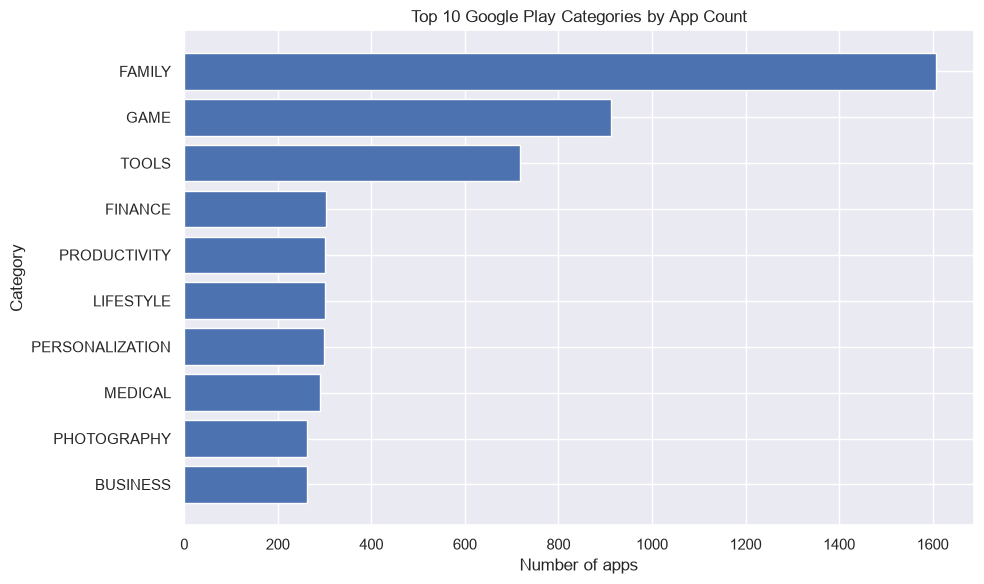

Observation 1: FAMILY has the highest app count (1608).
Observation 2: Among the ten displayed categories, BUSINESS has the lowest count (263).


In [50]:
top_categories = category_summary.head(10).sort_values("app_count")
plt.figure(figsize=(10, 6))
plt.barh(top_categories.index, top_categories["app_count"])
plt.title("Top 10 Google Play Categories by App Count")
plt.xlabel("Number of apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

largest_category = category_summary["app_count"].idxmax()
smallest_top10 = top_categories["app_count"].idxmin()
print(f"Observation 1: {largest_category} has the highest app count ({int(category_summary.loc[largest_category, 'app_count'])}).")
print(f"Observation 2: Among the ten displayed categories, {smallest_top10} has the lowest count ({int(top_categories.loc[smallest_top10, 'app_count'])}).")

## 8. Task 3 — Pivot table and crosstabulation

**Objective:** Summarise a numerical variable across two categorical dimensions and count combinations of categories.  
**Methodology:** `pivot_table()` uses mean rating by `Category` and `Price_Category`. `crosstab()` counts `Category` against `Content Rating`. The output is limited to the most frequent categories for readability.

In [51]:
top_cat_names = category_summary.head(10).index
pivot_rating = pd.pivot_table(
    apps_clean[apps_clean["Category"].isin(top_cat_names)],
    index="Category",
    columns="Price_Category",
    values="Rating_num",
    aggfunc="mean"
)
display(pivot_rating.round(2))

content_crosstab = pd.crosstab(
    apps_clean.loc[apps_clean["Category"].isin(top_cat_names), "Category"],
    apps_clean.loc[apps_clean["Category"].isin(top_cat_names), "Content Rating"],
    margins=True
)
display(content_crosstab)

Price_Category,Free,Paid
Category,,
BUSINESS,4.10,4.08
FAMILY,4.17,4.28
FINANCE,4.13,3.83
GAME,4.24,4.37
LIFESTYLE,4.08,4.25
MEDICAL,4.15,4.23
PERSONALIZATION,4.30,4.45
PHOTOGRAPHY,4.17,4.01
PRODUCTIVITY,4.18,4.21


Content Rating,Everyone,Everyone 10+,Mature 17+,Teen,Unrated,All
Category,,,,,,
BUSINESS,259,0,0,4,0,263
FAMILY,1238,105,44,221,0,1608
FINANCE,298,0,0,4,0,302
GAME,454,105,65,288,0,912
LIFESTYLE,270,5,9,17,0,301
MEDICAL,276,7,4,3,0,290
PERSONALIZATION,262,5,8,23,0,298
PHOTOGRAPHY,250,0,3,10,0,263
PRODUCTIVITY,297,1,1,2,0,301


## 9. Task 4 — Data reshaping

**Objective:** Demonstrate `melt()`, `pivot()`, `stack()` and `unstack()`.  
**Concept:** Wide format stores multiple measured variables in separate columns; long format stores a variable name and its value in rows. Reshaping supports plotting, comparison and integration.

In [52]:
# melt(): wide to long
wide_example = category_summary.head(5).reset_index()[["Category", "mean_rating", "median_rating", "median_price"]]
long_example = wide_example.melt(
    id_vars="Category",
    value_vars=["mean_rating", "median_rating", "median_price"],
    var_name="Metric",
    value_name="Value"
)
display(long_example)

# pivot(): long to wide; aggregate first to guarantee unique Category-Metric pairs
pivot_example = long_example.pivot(index="Category", columns="Metric", values="Value")
display(pivot_example)

# stack() and unstack() on a suitable MultiIndex table
stacked_example = pivot_rating.stack()
print("Stacked Series:")
display(stacked_example.head(10))
print("Unstacked back to wide:")
display(stacked_example.unstack().head())

,Category,Metric,Value
0,FAMILY,mean_rating,4.179726
1,GAME,mean_rating,4.247368
2,TOOLS,mean_rating,4.039415
3,FINANCE,mean_rating,4.115563
4,LIFESTYLE,mean_rating,4.093355
5,FAMILY,median_rating,4.300000
6,GAME,median_rating,4.300000
7,TOOLS,median_rating,4.200000
8,FINANCE,median_rating,4.300000
9,LIFESTYLE,median_rating,4.200000


Metric,mean_rating,median_price,median_rating
Category,,,
FAMILY,4.179726,0.0,4.3
FINANCE,4.115563,0.0,4.3
GAME,4.247368,0.0,4.3
LIFESTYLE,4.093355,0.0,4.2
TOOLS,4.039415,0.0,4.2


Stacked Series:


Category   Price_Category
BUSINESS   Free              4.098228
           Paid              4.077778
FAMILY     Free              4.168707
           Paid              4.283766
FINANCE    Free              4.128374
           Paid              3.830769
GAME       Free              4.236005
           Paid              4.372368
LIFESTYLE  Free              4.083392
           Paid              4.250000
dtype: float64

Unstacked back to wide:


Price_Category,Free,Paid
Category,,
BUSINESS,4.098228,4.077778
FAMILY,4.168707,4.283766
FINANCE,4.128374,3.830769
GAME,4.236005,4.372368
LIFESTYLE,4.083392,4.250000


## 10. Tasks 5 and 6 — Data integration and validation

**Objective:** Integrate at least two related tables and demonstrate `merge()`, `join()` and `concat()`, join types, key validation, suffixes, unmatched records and row-count checks.

**Available real data:** The uploaded archive has only the app table. To demonstrate an actual one-to-one integration without inventing observations, the app table is split into two complementary projections at the same app grain: app attributes and app metrics. They are merged on the app key. This is a derived integration demonstration, not a substitute for the missing genuine reviews table.

**Expected relationship:** One app record to one app record (`one_to_one`). The PRD's genuine review relationship is one app to many review records, keyed by `App`; that analysis is enabled below if `googleplaystore_user_reviews.csv` is added to `data/`.

In [53]:
app_attributes = apps_clean[["App", "Category", "Type", "Content Rating", "Genres"]].copy()
app_metrics = apps_clean[["App", "Rating_num", "Reviews_num", "Installs_num", "Price_num", "Size_MB"]].copy()

print("Attribute rows:", len(app_attributes), "| unique keys:", app_attributes["App"].nunique())
print("Metric rows:", len(app_metrics), "| unique keys:", app_metrics["App"].nunique())
print("Attribute duplicate keys:", int(app_attributes["App"].duplicated().sum()))
print("Metric duplicate keys:", int(app_metrics["App"].duplicated().sum()))

integrated_inner = app_attributes.merge(
    app_metrics, on="App", how="inner", validate="one_to_one",
    indicator=True, suffixes=("_attribute", "_metric")
)
print("Rows before integration:", len(app_attributes), "+", len(app_metrics))
print("Rows after inner merge:", len(integrated_inner))
display(integrated_inner.head())
print("\nMerge indicator:")
display(integrated_inner["_merge"].value_counts())

Attribute rows: 8196 | unique keys: 8196
Metric rows: 8196 | unique keys: 8196
Attribute duplicate keys: 0
Metric duplicate keys: 0
Rows before integration: 8196 + 8196
Rows after inner merge: 8196


,App,Category,Type,Content Rating,Genres,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB,_merge
0,+Download 4 Instagram Twitter,SOCIAL,Free,Everyone,Social,4.5,40467.0,1000000.0,0.0,22.000000,both
1,- Free Comics - Comic Apps,COMICS,Free,Mature 17+,Comics,3.5,115.0,10000.0,0.0,9.100000,both
2,.R,TOOLS,Free,Everyone,Tools,4.5,259.0,10000.0,0.0,0.198242,both
3,/u/app,COMMUNICATION,Free,Mature 17+,Communication,4.7,573.0,10000.0,0.0,53.000000,both
4,058.ba,NEWS_AND_MAGAZINES,Free,Everyone,News & Magazines,4.4,27.0,100.0,0.0,14.000000,both



Merge indicator:


_merge
both          8196
left_only        0
right_only       0
Name: count, dtype: int64

In [54]:
# Demonstrate all four join types and explain which side's records are retained.
join_counts = {}
for join_type in ["inner", "left", "right", "outer"]:
    joined = app_attributes[["App", "Category"]].merge(
        app_metrics[["App", "Rating_num"]],
        on="App", how=join_type, indicator=True
    )
    join_counts[join_type] = {
        "rows": len(joined),
        "both": int((joined["_merge"] == "both").sum()),
        "left_only": int((joined["_merge"] == "left_only").sum()),
        "right_only": int((joined["_merge"] == "right_only").sum())
    }
display(pd.DataFrame(join_counts).T)

# join(): set the key as index; overlapping columns use suffixes.
attributes_indexed = app_attributes.set_index("App")
metrics_indexed = app_metrics.set_index("App")
joined_by_index = attributes_indexed.join(
    metrics_indexed, how="left", lsuffix="_attributes", rsuffix="_metrics"
)
print("Index join row count:", len(joined_by_index))
display(joined_by_index.head())

# concat(): stack two compatible subsets and retain source labels.
sample_a = apps_clean[["App", "Category", "Rating_num"]].head(5).assign(Source_Part="Part A")
sample_b = apps_clean[["App", "Category", "Rating_num"]].iloc[5:10].assign(Source_Part="Part B")
concatenated = pd.concat([sample_a, sample_b], axis=0, ignore_index=True)
display(concatenated)

# Index alignment demonstration: values align by index labels, not row position.
left_series = pd.Series({"app_1": 10, "app_2": 20})
right_series = pd.Series({"app_2": 2, "app_3": 3})
print("Series index alignment:")
display(pd.concat([left_series.rename("left"), right_series.rename("right")], axis=1))

,rows,both,left_only,right_only
inner,8196,8196,0,0
left,8196,8196,0,0
right,8196,8196,0,0
outer,8196,8196,0,0


Index join row count: 8196


,Category,Type,Content Rating,Genres,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB
App,,,,,,,,,
+Download 4 Instagram Twitter,SOCIAL,Free,Everyone,Social,4.5,40467.0,1000000.0,0.0,22.000000
- Free Comics - Comic Apps,COMICS,Free,Mature 17+,Comics,3.5,115.0,10000.0,0.0,9.100000
.R,TOOLS,Free,Everyone,Tools,4.5,259.0,10000.0,0.0,0.198242
/u/app,COMMUNICATION,Free,Mature 17+,Communication,4.7,573.0,10000.0,0.0,53.000000
058.ba,NEWS_AND_MAGAZINES,Free,Everyone,News & Magazines,4.4,27.0,100.0,0.0,14.000000


,App,Category,Rating_num,Source_Part
0,+Download 4 Instagram Twitter,SOCIAL,4.5,Part A
1,- Free Comics - Comic Apps,COMICS,3.5,Part A
2,.R,TOOLS,4.5,Part A
3,/u/app,COMMUNICATION,4.7,Part A
4,058.ba,NEWS_AND_MAGAZINES,4.4,Part A
5,1. FC Köln App,SPORTS,4.6,Part B
6,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,Part B
7,10 Minutes a Day Times Tables,FAMILY,4.1,Part B
8,10 WPM Amateur ham radio CW Morse code trainer,COMMUNICATION,3.5,Part B
9,"10,000 Quotes DB (Premium)",BOOKS_AND_REFERENCE,4.1,Part B


Series index alignment:


,left,right
app_1,10.0,NaN
app_2,20.0,2.0
app_3,NaN,3.0


### Controlled one-to-many integration demonstration

The following tiny table is explicitly synthetic and is used only to illustrate the PRD's one-app-to-many-reviews relationship. It is not included in real-data findings, statistics or conclusions.

In [55]:
controlled_reviews = pd.DataFrame({
    "App": ["Demo App A", "Demo App A", "Demo App B"],
    "Review_ID": [1, 2, 3],
    "Sentiment": ["Positive", "Neutral", "Negative"]
})
controlled_apps = pd.DataFrame({"App": ["Demo App A", "Demo App B"], "Category": ["TOOLS", "EDUCATION"]})
controlled_merge = controlled_apps.merge(
    controlled_reviews, on="App", how="left", validate="one_to_many", indicator=True
)
print("Controlled demonstration only — not source observations:")
display(controlled_merge)
print("Parent app rows:", len(controlled_apps), "| merged review-level rows:", len(controlled_merge))

Controlled demonstration only — not source observations:


,App,Category,Review_ID,Sentiment,_merge
0,Demo App A,TOOLS,1,Positive,both
1,Demo App A,TOOLS,2,Neutral,both
2,Demo App B,EDUCATION,3,Negative,both


Parent app rows: 2 | merged review-level rows: 3


## 11. Task 7 — Measures of central tendency

**Objective:** Calculate mean, median and mode for at least two numerical variables.  
**Concept:** Mean is sensitive to extreme values; median is the middle observation; mode is the most frequent value. A large mean–median gap can indicate skewness or extreme observations.

In [56]:
central_vars = ["Rating_num", "Installs_num"]
central_rows = []
for col in central_vars:
    series = apps_clean[col].dropna()
    modes = series.mode()
    central_rows.append({
        "Variable": col,
        "Mean": series.mean(),
        "Median": series.median(),
        "Mode": modes.iloc[0] if len(modes) else np.nan,
        "Mean_minus_Median": series.mean() - series.median()
    })
central_tendency = pd.DataFrame(central_rows).set_index("Variable")
display(central_tendency)

,Mean,Median,Mode,Mean_minus_Median
Variable,,,,
Rating_num,4.173310e+00,4.3,4.4,-1.266898e-01
Installs_num,9.173716e+06,100000.0,1000000.0,9.073716e+06


## 12. Task 8 — Measures of dispersion

**Objective:** Calculate variance, standard deviation and range for suitable numerical variables.  
**Methodology:** Pandas `var()` and `std()` use sample statistics by default (`ddof=1`). Variance is expressed in squared units; standard deviation and range use the original units.

In [57]:
dispersion_rows = []
for col in ["Rating_num", "Installs_num"]:
    s = apps_clean[col].dropna()
    dispersion_rows.append({
        "Variable": col,
        "Sample variance (ddof=1)": s.var(ddof=1),
        "Sample standard deviation": s.std(ddof=1),
        "Range": s.max() - s.min(),
        "Minimum": s.min(),
        "Maximum": s.max(),
        "Units": "rating points" if col == "Rating_num" else "installs"
    })
display(pd.DataFrame(dispersion_rows).set_index("Variable"))

,Sample variance (ddof=1),Sample standard deviation,Range,Minimum,Maximum,Units
Variable,,,,,,
Rating_num,2.876893e-01,5.363668e-01,4.0,1.0,5.000000e+00,rating points
Installs_num,3.393388e+15,5.825279e+07,999999999.0,1.0,1.000000e+09,installs


## 13. Task 9 — Percentiles, quantiles and five-number summary

**Objective:** Calculate selected percentiles and the five-number summary.  
**Concept:** Q1, median and Q3 divide ordered observations into four parts. IQR = Q3 − Q1 and represents the spread of the middle 50%.

In [58]:
for col in ["Rating_num", "Installs_num"]:
    s = apps_clean[col].dropna()
    print(f"Percentiles and five-number summary: {col}")
    display(s.quantile([0.10, 0.25, 0.50, 0.75, 0.90]).rename("value").to_frame())
    q1, median, q3 = s.quantile([0.25, 0.50, 0.75])
    print({
        "minimum": s.min(), "Q1": q1, "median": median,
        "Q3": q3, "maximum": s.max(), "IQR": q3-q1
    })

Percentiles and five-number summary: Rating_num


,value
0.10,3.5
0.25,4.0
0.50,4.3
0.75,4.5
0.90,4.7


{'minimum': np.float64(1.0), 'Q1': 4.0, 'median': 4.3, 'Q3': 4.5, 'maximum': np.float64(5.0), 'IQR': 0.5}
Percentiles and five-number summary: Installs_num


,value
0.10,1000.0
0.25,10000.0
0.50,100000.0
0.75,1000000.0
0.90,10000000.0


{'minimum': np.float64(1.0), 'Q1': 10000.0, 'median': 100000.0, 'Q3': 1000000.0, 'maximum': np.float64(1000000000.0), 'IQR': 990000.0}


## 14. Task 10 — Skewness and kurtosis

**Objective:** Quantify distribution asymmetry and tail behaviour.  
**Concept:** Positive skew has a longer right tail; negative skew has a longer left tail. Pandas reports **excess kurtosis** (normal reference approximately 0). High positive excess kurtosis indicates heavier tails/more extreme values relative to a normal reference.

In [59]:
shape_rows = []
for col in ["Rating_num", "Installs_num", "Reviews_num", "Price_num"]:
    s = apps_clean[col].dropna()
    shape_rows.append({
        "Variable": col,
        "Skewness": s.skew(),
        "Excess kurtosis (Pandas)": s.kurt()
    })
shape_stats = pd.DataFrame(shape_rows).set_index("Variable")
display(shape_stats)

,Skewness,Excess kurtosis (Pandas)
Variable,,
Rating_num,-1.744219,5.128490
Installs_num,13.857434,216.331829
Reviews_num,24.511544,771.640310
Price_num,23.002377,534.600884


## 15. Task 11 — Common distributions

**Objective:** Use histograms, density curves and box plots to inspect actual numerical variables.  
**Decision:** The real app dataset is checked for normal, skewed and bimodal shapes. Distribution labels are not forced. If a clear normal, negative-skew or bimodal example is not present, controlled simulated data are used and labelled separately.

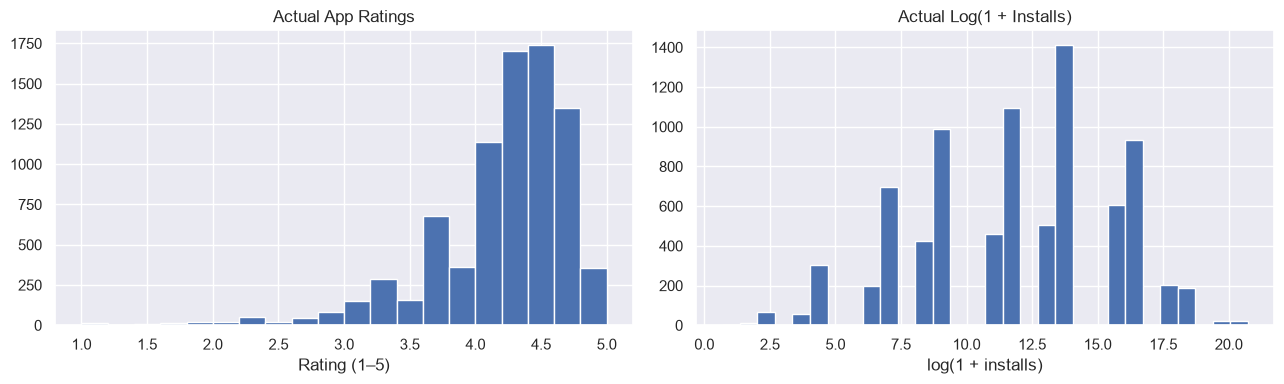

Actual rating skewness: -1.744
Actual installs skewness: 13.857


In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(apps_clean["Rating_num"].dropna(), bins=20)
axes[0].set_title("Actual App Ratings")
axes[0].set_xlabel("Rating (1–5)")
axes[1].hist(np.log1p(apps_clean["Installs_num"].dropna()), bins=30)
axes[1].set_title("Actual Log(1 + Installs)")
axes[1].set_xlabel("log(1 + installs)")
plt.tight_layout()
plt.show()

print("Actual rating skewness:", round(apps_clean["Rating_num"].skew(), 3))
print("Actual installs skewness:", round(apps_clean["Installs_num"].skew(), 3))

### Controlled distribution-shape examples

These generated arrays are simulations, not Google Play observations. They demonstrate normal, positively skewed, negatively skewed and bimodal shapes when the real dataset does not naturally provide clear examples of every required shape.

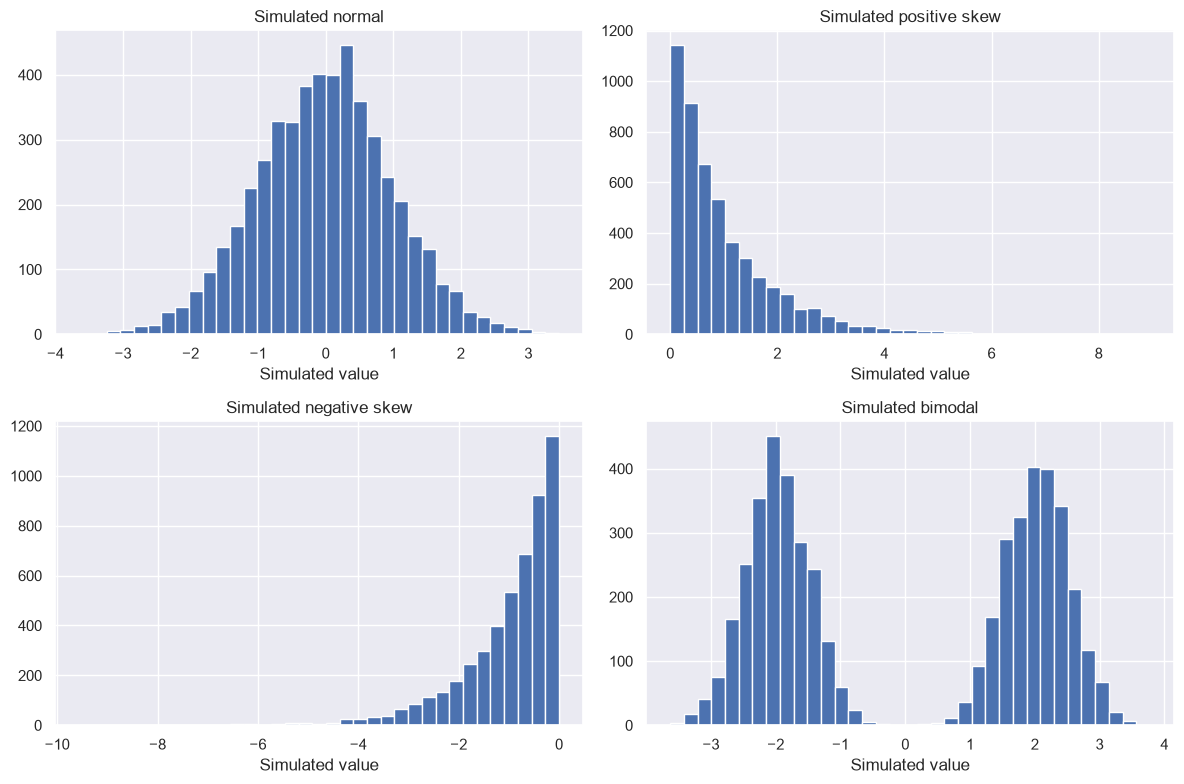

All four distributions above are controlled simulations, not source-data observations.


In [61]:
rng = np.random.default_rng(RANDOM_SEED)
sim_normal = rng.normal(0, 1, 5000)
sim_positive = rng.exponential(1, 5000)
sim_negative = -rng.exponential(1, 5000)
sim_bimodal = np.concatenate([rng.normal(-2, 0.5, 2500), rng.normal(2, 0.5, 2500)])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, values, title in zip(
    axes.ravel(),
    [sim_normal, sim_positive, sim_negative, sim_bimodal],
    ["Simulated normal", "Simulated positive skew", "Simulated negative skew", "Simulated bimodal"]
):
    ax.hist(values, bins=35)
    ax.set_title(title)
    ax.set_xlabel("Simulated value")
plt.tight_layout()
plt.show()
print("All four distributions above are controlled simulations, not source-data observations.")

## 16. Task 12 — Empirical rule (68–95–99.7)

**Objective:** Compare observed proportions within one, two and three standard deviations against the empirical rule.  
**Methodology:** The app rating distribution is inspected first. Because rating scores are bounded and may not be normally distributed, the primary demonstration uses a clearly labelled normal simulation. The real-data comparison is also reported without assuming that the rule must hold.

In [62]:
def empirical_rule_table(series):
    s = pd.Series(series).dropna()
    mean, sd = s.mean(), s.std(ddof=0)
    rows = []
    for k, expected in [(1, 68), (2, 95), (3, 99.7)]:
        observed = ((s >= mean-k*sd) & (s <= mean+k*sd)).mean() * 100
        rows.append({"Interval": f"Mean ± {k} SD", "Observed %": observed, "Reference %": expected})
    return pd.DataFrame(rows)

normal_sim_for_rule = rng.normal(100, 15, 10000)
print("Controlled normal simulation:")
display(empirical_rule_table(normal_sim_for_rule).round(2))
print("Actual app ratings (comparison only; normality is not assumed):")
display(empirical_rule_table(apps_clean["Rating_num"]).round(2))

Controlled normal simulation:


,Interval,Observed %,Reference %
0,Mean ± 1 SD,68.08,68.0
1,Mean ± 2 SD,95.26,95.0
2,Mean ± 3 SD,99.82,99.7


Actual app ratings (comparison only; normality is not assumed):


,Interval,Observed %,Reference %
0,Mean ± 1 SD,80.28,68.0
1,Mean ± 2 SD,94.78,95.0
2,Mean ± 3 SD,98.21,99.7


## 17. Task 13 — Sampling and Central Limit Theorem

**Objective:** Repeatedly sample from the app population, calculate sample means and inspect the sampling distribution.  
**Methodology:** Use a fixed random seed, simple random sampling without replacement within each repetition, sample size 30, and 1,000 repetitions. Compare sample sizes 10, 30 and 100. The population here is the valid app-level dataset, not every Android app in existence.

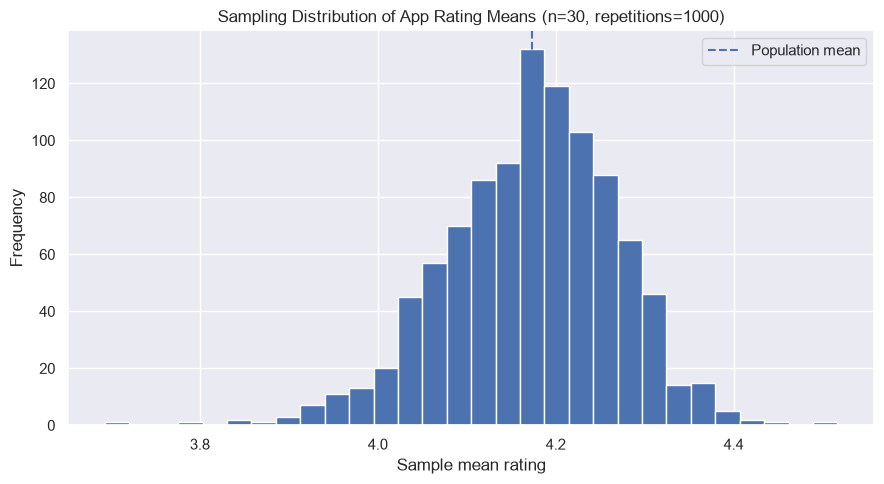

,Mean of sample means,SD of sample means
Sample size,,
10,4.177110,0.165229
30,4.171233,0.098330
100,4.176711,0.051117


Sampling method: simple random sampling without replacement.
Fixed random seed: 42 | repetitions: 1000


In [63]:
rating_population = apps_clean["Rating_num"].dropna().to_numpy()
rng_clt = np.random.default_rng(RANDOM_SEED)
n_repetitions = 1000
sample_size = min(30, len(rating_population))
sample_means = np.array([
    rng_clt.choice(rating_population, size=sample_size, replace=False).mean()
    for _ in range(n_repetitions)
])

plt.figure(figsize=(9, 5))
plt.hist(sample_means, bins=30)
plt.axvline(rating_population.mean(), linestyle="--", label="Population mean")
plt.title(f"Sampling Distribution of App Rating Means (n={sample_size}, repetitions={n_repetitions})")
plt.xlabel("Sample mean rating")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

comparison = []
for n in [10, 30, 100]:
    n = min(n, len(rating_population))
    means = [rng_clt.choice(rating_population, size=n, replace=False).mean() for _ in range(n_repetitions)]
    comparison.append({"Sample size": n, "Mean of sample means": np.mean(means), "SD of sample means": np.std(means, ddof=1)})
display(pd.DataFrame(comparison).set_index("Sample size"))
print("Sampling method: simple random sampling without replacement.")
print("Fixed random seed:", RANDOM_SEED, "| repetitions:", n_repetitions)

## 18. Task 14 — Covariance and correlation

**Objective:** Calculate covariance, Pearson correlation and Spearman correlation for numerical variables.  
**Concept:** Pearson measures linear association; Spearman measures monotonic rank association. Correlation ranges from −1 to +1. Covariance depends on variable scales and units. Correlation does not establish causation.

In [64]:
correlation_data = apps_clean[["Rating_num", "Reviews_num", "Installs_num", "Price_num", "Size_MB"]].dropna()
selected_pair = correlation_data[["Reviews_num", "Installs_num"]]

print("Covariance matrix:")
display(correlation_data.cov().round(3))
print("Pearson correlation:")
display(correlation_data.corr(method="pearson").round(3))
print("Spearman correlation:")
display(correlation_data.corr(method="spearman").round(3))

Covariance matrix:


,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB
Rating_num,0.312,3.869310e+04,7.181857e+05,-0.214,7.980000e-01
Reviews_num,38693.098,1.048342e+12,1.655153e+13,-167599.587,4.199219e+06
Installs_num,718185.656,1.655153e+13,7.366143e+14,-5201009.632,8.110222e+07
Price_num,-0.214,-1.675996e+05,-5.201010e+06,331.055,-1.061600e+01
Size_MB,0.798,4.199219e+06,8.110222e+07,-10.616,5.164300e+02


Pearson correlation:


,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB
Rating_num,1.000,0.068,0.047,-0.021,0.063
Reviews_num,0.068,1.000,0.596,-0.009,0.180
Installs_num,0.047,0.596,1.000,-0.011,0.131
Price_num,-0.021,-0.009,-0.011,1.000,-0.026
Size_MB,0.063,0.180,0.131,-0.026,1.000


Spearman correlation:


,Rating_num,Reviews_num,Installs_num,Price_num,Size_MB
Rating_num,1.000,0.087,-0.003,0.063,0.050
Reviews_num,0.087,1.000,0.958,-0.158,0.355
Installs_num,-0.003,0.958,1.000,-0.255,0.328
Price_num,0.063,-0.158,-0.255,1.000,-0.043
Size_MB,0.050,0.355,0.328,-0.043,1.000


### Correlation heatmap and scatter plot

Two observations are printed from the actual correlation matrix. The scatter plot uses a log-scaled x-axis because install counts span a wide range.

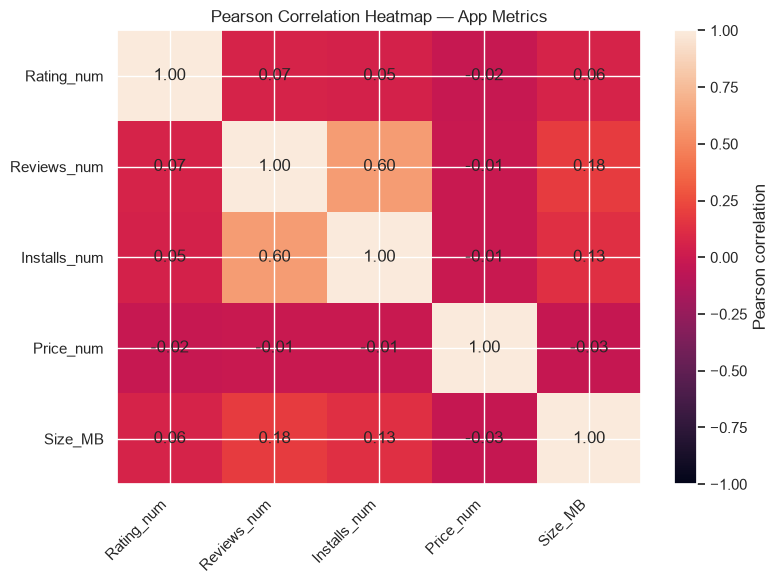

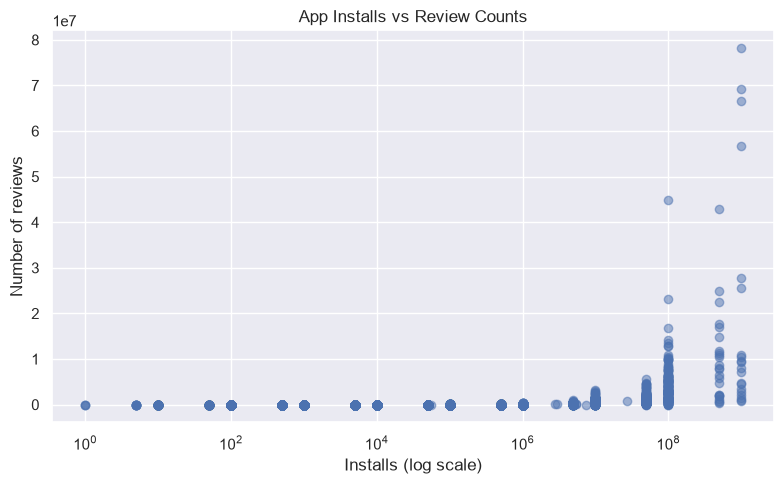

Observation 1: Pearson correlation between installs and review counts = 0.624.
Observation 2: Spearman correlation between installs and review counts = 0.960.
A difference between Pearson and Spearman can indicate skew, outliers or a non-linear monotonic relationship.
These are associations only; they do not prove that installs cause reviews.


In [65]:
corr_matrix = correlation_data.corr(method="pearson")
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr_matrix.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.index)), corr_matrix.index)
ax.set_title("Pearson Correlation Heatmap — App Metrics")
for i in range(len(corr_matrix.index)):
    for j in range(len(corr_matrix.columns)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(apps_clean["Installs_num"], apps_clean["Reviews_num"], alpha=0.5)
plt.xscale("log")
plt.title("App Installs vs Review Counts")
plt.xlabel("Installs (log scale)")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

pearson_ri = apps_clean[["Reviews_num", "Installs_num"]].corr(method="pearson").iloc[0, 1]
spearman_ri = apps_clean[["Reviews_num", "Installs_num"]].corr(method="spearman").iloc[0, 1]
print(f"Observation 1: Pearson correlation between installs and review counts = {pearson_ri:.3f}.")
print(f"Observation 2: Spearman correlation between installs and review counts = {spearman_ri:.3f}.")
print("A difference between Pearson and Spearman can indicate skew, outliers or a non-linear monotonic relationship.")
print("These are associations only; they do not prove that installs cause reviews.")

## 19. Tasks 15 and 16 — Outlier detection and handling

**Objective:** Detect potential outliers using IQR and Z-score methods, compare removal/capping/retention, and assess the effect on summary statistics.  
**Variable:** `Reviews_num`, a non-negative count variable with a likely right-skewed distribution.  
**Methods:** IQR fences use Q1 − 1.5×IQR and Q3 + 1.5×IQR. Z-score threshold is |Z| > 3. Both methods are exploratory; flagged values must be inspected before a decision.

In [66]:
outlier_series = apps_clean["Reviews_num"].dropna()
q1, q3 = outlier_series.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
iqr_mask = (outlier_series < lower_fence) | (outlier_series > upper_fence)

z_scores = (outlier_series - outlier_series.mean()) / outlier_series.std(ddof=0)
z_mask = z_scores.abs() > 3

outlier_report = pd.DataFrame({
    "Method": ["IQR", "Z-score (|Z| > 3)"],
    "Outlier count": [int(iqr_mask.sum()), int(z_mask.sum())],
    "Proportion (%)": [iqr_mask.mean()*100, z_mask.mean()*100]
})
display(outlier_report.round(3))
print({"Q1": q1, "Q3": q3, "IQR": iqr, "lower_fence": lower_fence, "upper_fence": upper_fence})
print("Largest flagged review counts:")
display(outlier_series.loc[iqr_mask].sort_values(ascending=False).head(10).to_frame("Reviews_num"))

,Method,Outlier count,Proportion (%)
0,IQR,1388,16.935
1,Z-score (|Z| > 3),57,0.695


{'Q1': 126.75, 'Q3': 43976.75, 'IQR': 43850.0, 'lower_fence': -65648.25, 'upper_fence': 109751.75}
Largest flagged review counts:


,Reviews_num
4328,78143257.0
9042,69119316.0
5399,66577313.0
6166,56642847.0
2564,44891723.0
2573,42916526.0
8080,27723643.5
9226,25639426.5
7722,24900999.0
2561,23134141.5


### Compare removal, capping and retention

The original values are preserved. Each strategy is applied to a separate Series:
- **Removal:** excludes IQR-flagged observations for a sensitivity comparison only.
- **Capping:** clips values at the IQR fences.
- **Retention:** keeps all valid values. This is the default decision because large review counts may represent genuinely popular apps, not errors.

,Rows,Mean,Median,Std dev,Range
Strategy,,,,,
Retention (default),8196,255320.72,3015.5,1985499.94,78143256.00
Removal (sensitivity only),6808,12121.34,1012.5,22244.20,109499.00
Capping (sensitivity only),8196,28655.14,3015.5,41856.86,109750.75


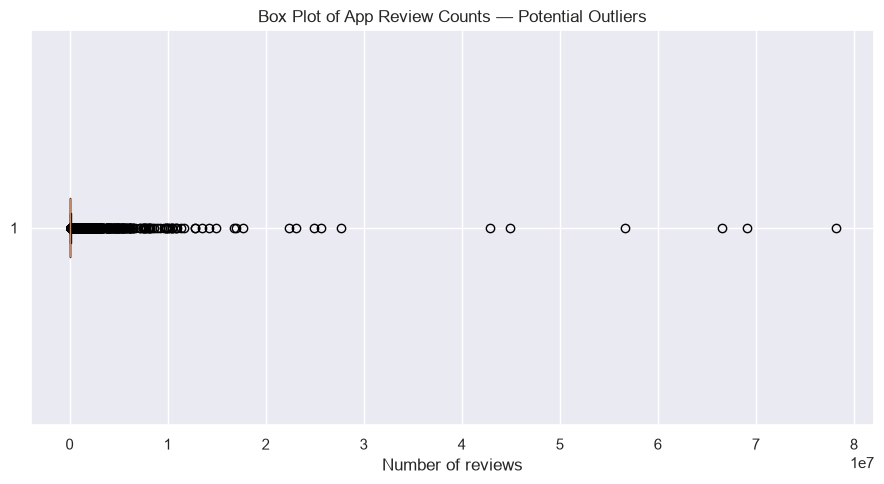

Decision: retain valid extreme values by default; removal/capping are sensitivity analyses, not automatic cleaning.


In [67]:
retained = outlier_series.copy()
removed = outlier_series.loc[~iqr_mask].copy()
capped = outlier_series.clip(lower=lower_fence, upper=upper_fence)

def summary_stats(series, label):
    return {
        "Strategy": label,
        "Rows": len(series),
        "Mean": series.mean(),
        "Median": series.median(),
        "Std dev": series.std(),
        "Range": series.max() - series.min()
    }

handling_comparison = pd.DataFrame([
    summary_stats(retained, "Retention (default)"),
    summary_stats(removed, "Removal (sensitivity only)"),
    summary_stats(capped, "Capping (sensitivity only)")
]).set_index("Strategy")
display(handling_comparison.round(2))

plt.figure(figsize=(9, 5))
plt.boxplot(outlier_series, vert=False)
plt.title("Box Plot of App Review Counts — Potential Outliers")
plt.xlabel("Number of reviews")
plt.tight_layout()
plt.show()
print("Decision: retain valid extreme values by default; removal/capping are sensitivity analyses, not automatic cleaning.")

## 21. Findings and observations

The following findings are calculated from the cleaned app-level table. They describe this Kaggle snapshot only; they should not be generalised to all apps in the Google Play Store or interpreted causally.

In [68]:
findings = {
    "Number of app-level records analysed": len(apps_clean),
    "Number of app categories": apps_clean["Category"].nunique(),
    "Median app rating": apps_clean["Rating_num"].median(),
    "Mean app rating": apps_clean["Rating_num"].mean(),
    "Median installs": apps_clean["Installs_num"].median(),
    "Free app share (%)": apps_clean["Price_Category"].eq("Free").mean() * 100,
    "Apps with valid update date": apps_clean["Last_Updated_dt"].notna().sum(),
    "Pearson correlation: installs vs reviews": apps_clean[["Installs_num", "Reviews_num"]].corr().iloc[0, 1],
    "Spearman correlation: installs vs reviews": apps_clean[["Installs_num", "Reviews_num"]].corr(method="spearman").iloc[0, 1]
}
display(pd.Series(findings, name="Actual result").to_frame())

,Actual result
Number of app-level records analysed,8196.000000
Number of app categories,33.000000
Median app rating,4.300000
Mean app rating,4.173310
Median installs,100000.000000
Free app share (%),92.630551
Apps with valid update date,8196.000000
Pearson correlation: installs vs reviews,0.624016
Spearman correlation: installs vs reviews,0.959636


## 22. Limitations and future scope

1. Consequently, genuine review-text sentiment analysis and the intended app-to-review one-to-many integration cannot be completed from the supplied files alone.
2. The source contains duplicate app names and inconsistent/missing values. The notebook consolidates duplicate names at app level using documented aggregation.
3. Installs are reported in bands in the original source (for example, `1,000+`), so parsed values are approximate lower-bound-style counts, not exact installation totals.
4. Rating and review variables may be skewed and affected by app popularity. Correlation is not causation.
5. The dataset is a historical Kaggle snapshot and does not represent the current Play Store.
6. Controlled simulated distributions are pedagogical demonstrations and are never presented as source observations.

**Future scope:** Add the genuine `googleplaystore_user_reviews.csv`, aggregate sentiment polarity and subjectivity per app, validate app-name matches, compare review sentiment with app ratings, and revisit the integration and findings using the full two-table dataset.

## 23. Final conclusion

This exploratory analysis applies the required Unit IV and Unit V techniques to the supplied Google Play Store app dataset. It covers data understanding and quality checks, feature engineering, grouping and aggregation, pivot tables, crosstabulation, reshaping, table integration demonstrations, descriptive statistics, distribution analysis, the empirical rule, sampling and CLT, covariance and correlation, and outlier detection and treatment.

The analysis preserves the raw data, documents transformations, uses a fixed random seed, and distinguishes real observations from controlled simulations. The most important remaining dependency is the genuine `googleplaystore_user_reviews.csv` file: adding it will allow the project to complete the PRD's intended app-to-review integration and real review-sentiment analysis.

